<a href="https://colab.research.google.com/github/Pranov1984/Bankrupty-Prediction/blob/main/Bankruptcy_Prediction_Applied_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1><font size=6>Bankruptcy Prediction with Machine Learning on an Imbalanced Dataset</font></h1></center>
<center><h3>Applied Machine Learning</h3></center>

## Problem Statement

### Business Context

Banks, lenders and investors need to know early whether a company is heading towards bankruptcy. A company that fails after receiving a loan or an investment can cause large losses, so a model that flags risky companies from their financial statements is very valuable.

The data for this problem has a catch: only a small share of companies actually go bankrupt. A model trained on such data can look very accurate by simply predicting "not bankrupt" for everyone, while missing the companies that matter the most.

### Problem Definition

We have financial indicators (profitability, liquidity, leverage, turnover and growth ratios) for a set of companies, and a label that says whether each company went bankrupt. The goal is to predict bankruptcy, with the focus on the minority (bankrupt) class. Three challenges need to be handled:

1. **Class imbalance:** bankrupt companies are a tiny fraction of the data
2. **High dimensionality:** many features can cause overfitting and long training times
3. **Type 2 errors:** failing to predict bankruptcy for a company that really goes bankrupt (a false negative) is the costly mistake, so the aim is to reduce it

A **Type 1 error** is the opposite mistake: flagging a healthy company as bankrupt (a false positive). Reducing Type 2 errors usually increases Type 1 errors, so we look at both.

## Methodology

**Exploratory Data Analysis:** We check the class imbalance and the distribution of the features, and see which features are related to bankruptcy.

**Dimensionality Reduction:** We remove constant and highly correlated features and then keep the most important features using Random Forest feature importance. We compare the training time before and after.

**Data Splitting and Class Balancing:** We split the data into train and test sets (stratified) and balance only the training data with SMOTE (oversampling) and random undersampling. The test set is never balanced, so it reflects real life.

**Model Training and Evaluation:** We train Logistic Regression, KNN, Decision Tree, Neural Network, Random Forest and Gradient Boosting on the original and the balanced data. We evaluate them with accuracy, precision, recall, F1-score, ROC-AUC and the confusion matrix.

**Comparison of Results:** We compare the models before and after balancing, with a focus on how the Type 2 errors change.

## Objective

Build and compare machine learning models that predict company bankruptcy, and show how class balancing and feature selection change the performance, especially the number of bankrupt companies the model fails to catch (Type 2 errors).

### Before running the notebook

1. Upload `Dataset.csv` to Colab (folder icon in the left sidebar → upload) or place it in your Google Drive and change `data_path` in the settings cell
2. No GPU is needed, the default CPU runtime is fine
3. Run the cells from top to bottom. The full run takes a few minutes, mostly for Gradient Boosting and the optional robustness check at the end.

## Importing the necessary libraries

In [1]:
# installing imbalanced-learn, which has SMOTE and the undersampling methods
!pip install imbalanced-learn -q

In [3]:
# Import necessary libraries for data manipulation and analysis
import time
import warnings
import numpy as np
import pandas as pd

# Import visualization libraries
import seaborn as sns
import matplotlib.pyplot as plt

# Import modules from scikit-learn for machine learning tasks
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, classification_report)

# Import the class balancing methods
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# To hide the warnings
warnings.filterwarnings('ignore')

### Setting the parameters

In [4]:
# path of the dataset (change this if you load the file from Google Drive)
data_path = '/content/Dataset.csv'

# name of the target column
target = 'Bankrupt?'

# fixed values so that the results can be reproduced
seed = 42
test_size = 0.20

# features with a correlation above this value with another feature are treated as duplicates
corr_threshold = 0.95

# number of features to keep after the Random Forest feature importance step
top_k = 30

# setting the plot style
sns.set_style('whitegrid')

## Loading the dataset

In [5]:
# reading the csv file
df = pd.read_csv(data_path)

# some column names start with a blank space, so we remove it
df.columns = df.columns.str.strip()

## Data Overview

### Checking the first five rows of the data

In [6]:
df.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


### Checking the shape of the dataset

In [7]:
print('Rows   :', df.shape[0])
print('Columns:', df.shape[1])

Rows   : 6819
Columns: 96


### Checking the data types and missing values

In [8]:
# number of columns of each data type
print(df.dtypes.value_counts())

# columns having missing values
missing = df.isnull().sum()
print('\nColumns with missing values:', (missing > 0).sum())
print('Duplicate rows             :', df.duplicated().sum())

float64    93
int64       3
Name: count, dtype: int64

Columns with missing values: 0
Duplicate rows             : 0


- All the columns are numeric and there are no missing values or duplicate rows, so no imputation is needed

### Checking the statistical summary

In [9]:
df.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
Bankrupt?,6819.0,3.226280e-02,1.767102e-01,0.0,0.000000,0.000000e+00,0.000000e+00,1.000000e+00
ROA(C) before interest and depreciation before interest,6819.0,5.051796e-01,6.068564e-02,0.0,0.476527,5.027056e-01,5.355628e-01,1.000000e+00
ROA(A) before interest and % after tax,6819.0,5.586249e-01,6.562003e-02,0.0,0.535543,5.598016e-01,5.891572e-01,1.000000e+00
ROA(B) before interest and depreciation after tax,6819.0,5.535887e-01,6.159481e-02,0.0,0.527277,5.522780e-01,5.841051e-01,1.000000e+00
Operating Gross Margin,6819.0,6.079480e-01,1.693381e-02,0.0,0.600445,6.059975e-01,6.139142e-01,1.000000e+00
Realized Sales Gross Margin,6819.0,6.079295e-01,1.691607e-02,0.0,0.600434,6.059759e-01,6.138421e-01,1.000000e+00
Operating Profit Rate,6819.0,9.987551e-01,1.301003e-02,0.0,0.998969,9.990222e-01,9.990945e-01,1.000000e+00
Pre-tax net Interest Rate,6819.0,7.971898e-01,1.286899e-02,0.0,0.797386,7.974636e-01,7.975788e-01,1.000000e+00
After-tax net Interest Rate,6819.0,8.090836e-01,1.360065e-02,0.0,0.809312,8.093752e-01,8.094693e-01,1.000000e+00
Non-industry income and expenditure/revenue,6819.0,3.036229e-01,1.116344e-02,0.0,0.303466,3.035255e-01,3.035852e-01,1.000000e+00


### Checking for constant columns

In [10]:
# a column with a single unique value carries no information for the model
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print('Constant columns:', constant_cols)

Constant columns: ['Net Income Flag']


- A constant column cannot help in separating bankrupt from healthy companies, so it is dropped later

## Exploratory Data Analysis

### Checking the class imbalance

In [11]:
# count and share of each class (0 = not bankrupt, 1 = bankrupt)
class_counts = df[target].value_counts()
class_share = df[target].value_counts(normalize=True) * 100

print(pd.DataFrame({'count': class_counts, 'share (%)': class_share.round(2)}))
print('\nImbalance ratio (majority : minority) = %.0f : 1' % (class_counts[0] / class_counts[1]))

           count  share (%)
Bankrupt?                  
0           6599      96.77
1            220       3.23

Imbalance ratio (majority : minority) = 30 : 1


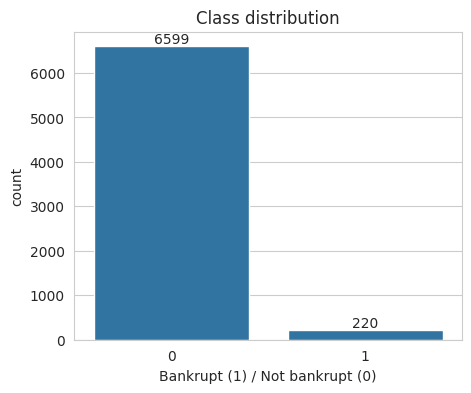

In [12]:
# plotting the class distribution
plt.figure(figsize=(5, 4))
ax = sns.countplot(x=target, data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Class distribution')
plt.xlabel('Bankrupt (1) / Not bankrupt (0)')
plt.show()

- The data is heavily imbalanced: only about 3% of the companies are bankrupt, roughly 30 healthy companies for every bankrupt one

### Why accuracy alone is misleading here

In [13]:
# a "model" that always predicts the majority class (not bankrupt)
baseline_accuracy = class_counts.max() / class_counts.sum()
print('Accuracy of always predicting "not bankrupt": %.2f%%' % (baseline_accuracy * 100))
print('Bankrupt companies it catches            : 0 out of %d' % class_counts[1])

Accuracy of always predicting "not bankrupt": 96.77%
Bankrupt companies it catches            : 0 out of 220


- A model that never predicts bankruptcy still gets an accuracy of about 97%, but it is useless because it catches none of the bankrupt companies. This is the accuracy paradox, so we focus on recall, precision, F1-score and the confusion matrix for the bankrupt class

### Checking the distribution of the features

In [14]:
# skewness of every feature (a value far from 0 means a long tail on one side)
features = df.drop(columns=[target] + constant_cols)
skewness = features.skew().sort_values(ascending=False)

print('Features with |skew| > 10:', (skewness.abs() > 10).sum(), 'out of', features.shape[1])
print('\nMost skewed features:')
print(skewness.head(8).round(1))

Features with |skew| > 10: 48 out of 94

Most skewed features:
Fixed Assets to Assets                     82.6
Current Ratio                              82.6
Total income/Total expense                 82.3
Net Value Growth Rate                      80.3
Contingent liabilities/Net worth           79.7
Realized Sales Gross Profit Growth Rate    77.9
Continuous Net Profit Growth Rate          67.1
Total Asset Return Growth Rate Ratio       62.5
dtype: float64


In [15]:
# columns with very large values (most of the ratios in this data are between 0 and 1)
max_values = features.max().sort_values(ascending=False)
print('Features with a maximum above 1,000,000:', (max_values > 1e6).sum())
print(max_values.head(8))

Features with a maximum above 1,000,000: 24
Current Asset Turnover Rate              1.000000e+10
Cash Turnover Rate                       1.000000e+10
Quick Asset Turnover Rate                1.000000e+10
Fixed Assets Turnover Frequency          9.990000e+09
Operating Expense Rate                   9.990000e+09
Total Asset Growth Rate                  9.990000e+09
Inventory Turnover Rate (times)          9.990000e+09
Research and development expense rate    9.980000e+09
dtype: float64


- Most of the features are ratios between 0 and 1, but some of them (for example the turnover rates) have extreme values of the order of 10 billion, which makes them very skewed
- Such values would distort models that depend on distances or on a linear fit (KNN, Logistic Regression, Neural Network), so we transform the features before modelling

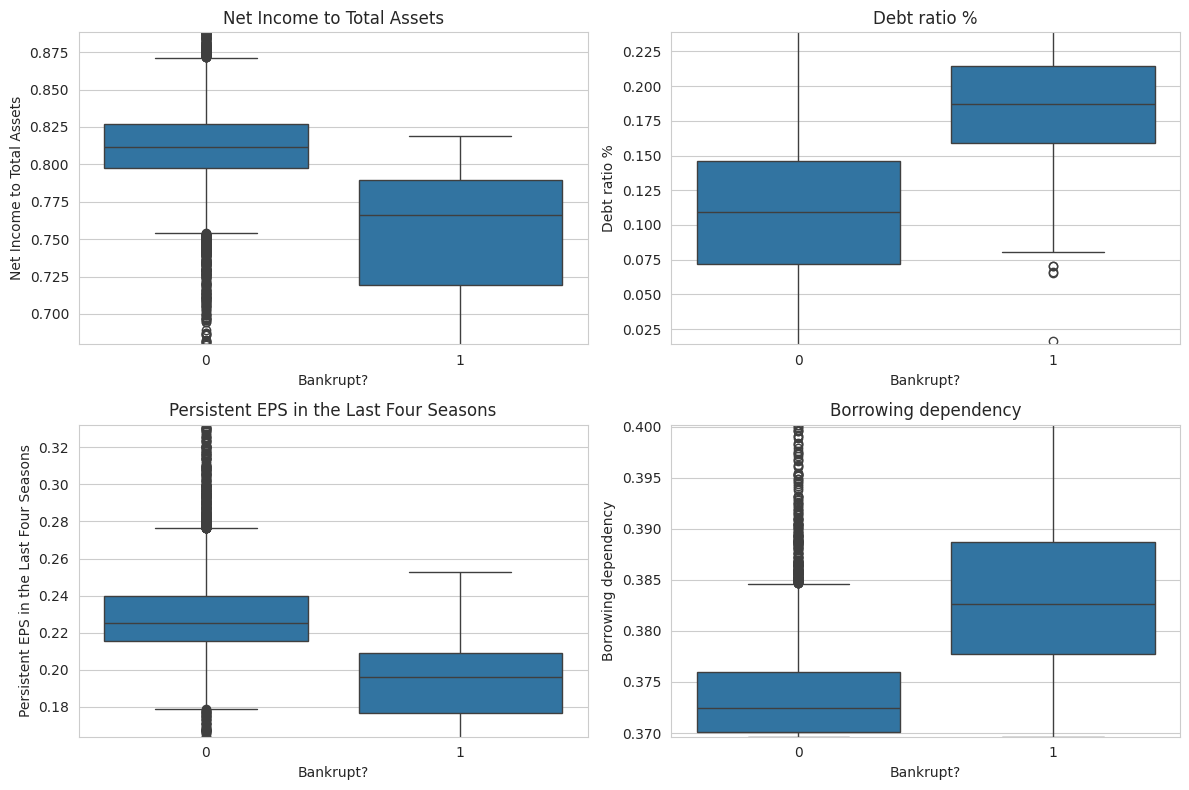

In [16]:
# comparing the distribution of a few important features for the two classes
top_features = ['Net Income to Total Assets', 'Debt ratio %',
                'Persistent EPS in the Last Four Seasons', 'Borrowing dependency']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), top_features):
    sns.boxplot(x=target, y=col, data=df, ax=ax)
    # zooming into the 1st to 99th percentile so that a few outliers do not squash the boxes
    low, high = df[col].quantile([0.01, 0.99])
    ax.set_ylim(low, high)
    ax.set_title(col)
plt.tight_layout()
plt.show()

- Bankrupt companies have a lower return on assets and lower earnings per share, and higher debt and borrowing dependency than healthy companies

### Checking the correlation of the features with bankruptcy

In [17]:
# correlation of every feature with the target
corr_with_target = features.corrwith(df[target]).sort_values()

print('Most negatively correlated with bankruptcy:')
print(corr_with_target.head(6).round(3))
print('\nMost positively correlated with bankruptcy:')
print(corr_with_target.tail(6).round(3))

Most negatively correlated with bankruptcy:
Net Income to Total Assets                                -0.315
ROA(A) before interest and % after tax                    -0.283
ROA(B) before interest and depreciation after tax         -0.273
ROA(C) before interest and depreciation before interest   -0.261
Net worth/Assets                                          -0.250
Persistent EPS in the Last Four Seasons                   -0.220
dtype: float64

Most positively correlated with bankruptcy:
Current Liabilities/Equity             0.154
Liability to Equity                    0.167
Current Liability to Current Assets    0.171
Borrowing dependency                   0.177
Current Liability to Assets            0.194
Debt ratio %                           0.250
dtype: float64


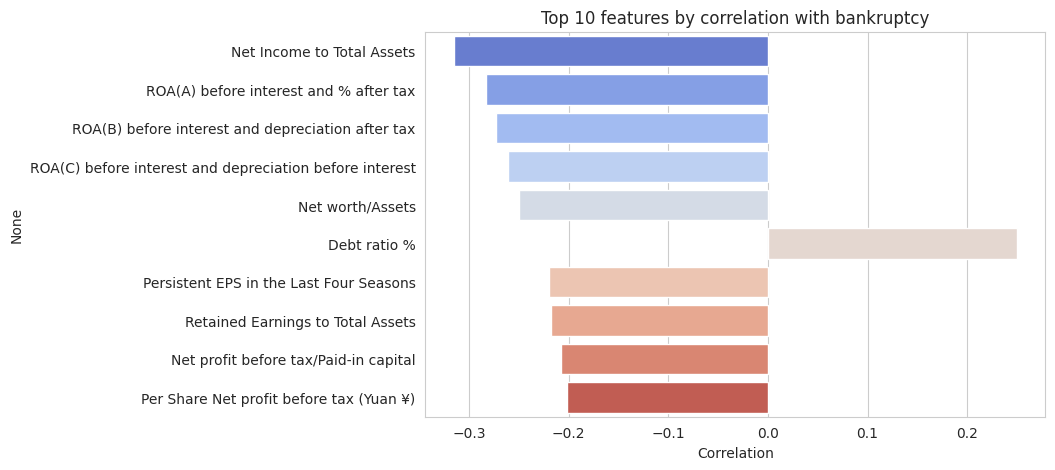

In [18]:
# plotting the 10 features with the strongest correlation (positive or negative)
strongest = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=strongest.values, y=strongest.index, palette='coolwarm')
plt.title('Top 10 features by correlation with bankruptcy')
plt.xlabel('Correlation')
plt.show()

- Profitability measures (return on assets, net income to total assets) are negatively related to bankruptcy and leverage measures (debt ratio, borrowing dependency) are positively related, which matches what we would expect
- No single feature has a very strong relationship (all below 0.35), so a combination of features is needed

### Checking the correlation between the features

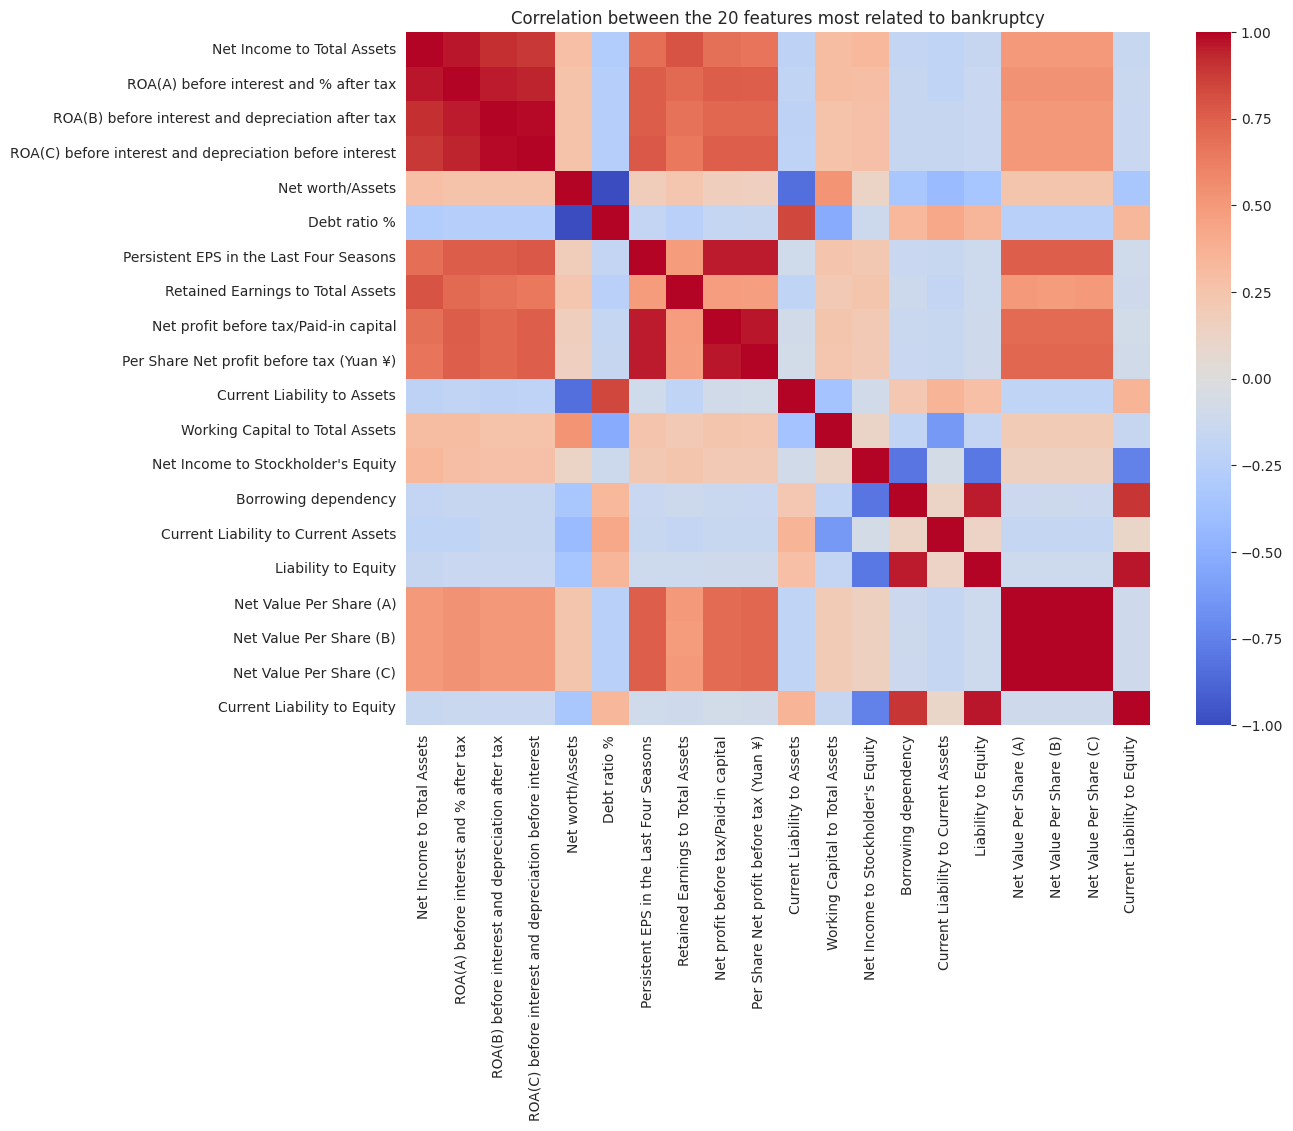

In [19]:
# heatmap of the correlation between the 20 features most related to the target
top20 = corr_with_target.abs().sort_values(ascending=False).head(20).index

plt.figure(figsize=(12, 9))
sns.heatmap(features[top20].corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation between the 20 features most related to bankruptcy')
plt.show()

In [20]:
# number of features that have a partner with a correlation above 0.95
corr_matrix = features.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
print('Features with a correlation above %.2f with another feature: %d' %
      (corr_threshold, (upper > corr_threshold).any().sum()))

Features with a correlation above 0.95 with another feature: 16


- Many features are almost copies of each other (for example the different return on assets measures). This is redundant information that makes the models slower without making them better, so we remove it in the dimensionality reduction step

## Data Preprocessing

### Splitting the data into train and test sets

We split the data first and do all the other steps (scaling, feature selection, balancing) on the training data only. If we did them before the split, information from the test set would leak into the training and the results would look better than they really are.

In [21]:
# separating the features and the target, and dropping the constant column
X = df.drop(columns=[target] + constant_cols)
y = df[target]

# stratified split keeps the same share of bankrupt companies in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, stratify=y, random_state=seed)

print('Train :', X_train.shape, '| bankrupt = %d (%.2f%%)' % (y_train.sum(), y_train.mean() * 100))
print('Test  :', X_test.shape, '| bankrupt = %d (%.2f%%)' % (y_test.sum(), y_test.mean() * 100))

Train : (5455, 94) | bankrupt = 176 (3.23%)
Test  : (1364, 94) | bankrupt = 44 (3.23%)


- The test set has only a few dozen bankrupt companies, so each missed company changes the recall by about 2 percentage points. Keep this in mind while reading the results

### Transforming the features

The extreme values and the skew are handled with a `QuantileTransformer`, which maps every feature to a normal-like shape based on its ranks. It is not affected by the 10-billion values, and it is fitted on the training data only.

In [22]:
# fitting the transformer on the train data and applying it to both the train and the test data
qt = QuantileTransformer(output_distribution='normal', n_quantiles=1000, random_state=seed)

X_train_t = pd.DataFrame(qt.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_t = pd.DataFrame(qt.transform(X_test), columns=X.columns, index=X_test.index)

print('Max absolute value in the train data after the transformation: %.2f' % X_train_t.abs().max().max())

Max absolute value in the train data after the transformation: 5.20


## Dimensionality Reduction

We reduce the 94 features in two steps: first remove the features that are nearly duplicates of another one, then keep the most important of the remaining ones.

### Removing highly correlated features

In [23]:
# for every pair of features with a correlation above the threshold, we drop one of the two
corr_train = X_train_t.corr().abs()
upper = corr_train.where(np.triu(np.ones(corr_train.shape), k=1).astype(bool))

to_drop = [col for col in upper.columns if (upper[col] > corr_threshold).any()]
features_after_corr = [c for c in X_train_t.columns if c not in to_drop]

print('Features before:', X_train_t.shape[1])
print('Dropped        :', len(to_drop))
print('Features after :', len(features_after_corr))

Features before: 94
Dropped        : 23
Features after : 71


### Selecting the most important features with Random Forest

In [24]:
# a Random Forest gives an importance score to every feature
# class_weight='balanced_subsample' makes it pay attention to the bankrupt class while scoring the features
rf_selector = RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample',
                                     random_state=seed, n_jobs=-1)
rf_selector.fit(X_train_t[features_after_corr], y_train)

importances = pd.Series(rf_selector.feature_importances_, index=features_after_corr).sort_values(ascending=False)
selected_features = list(importances.head(top_k).index)

print('Selected features:', len(selected_features))
print('Share of the total importance kept: %.1f%%' % (importances.head(top_k).sum() * 100))

Selected features: 30
Share of the total importance kept: 77.3%


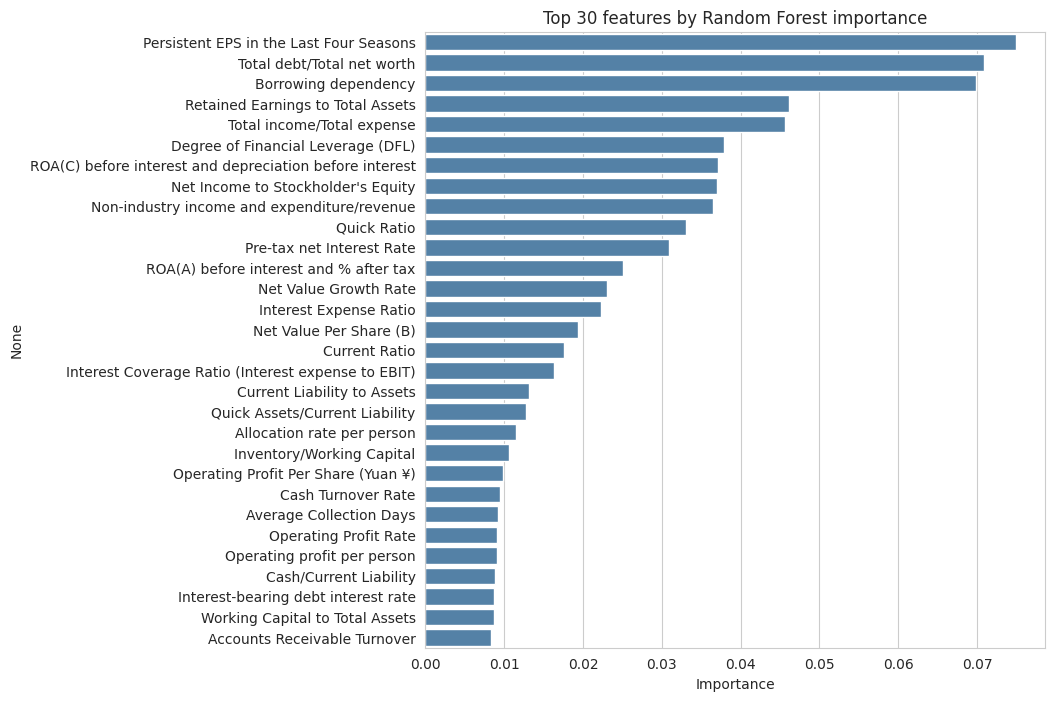

In [25]:
# plotting the importance of the selected features
plt.figure(figsize=(8, 8))
sns.barplot(x=importances.head(top_k).values, y=importances.head(top_k).index, color='steelblue')
plt.title('Top %d features by Random Forest importance' % top_k)
plt.xlabel('Importance')
plt.show()

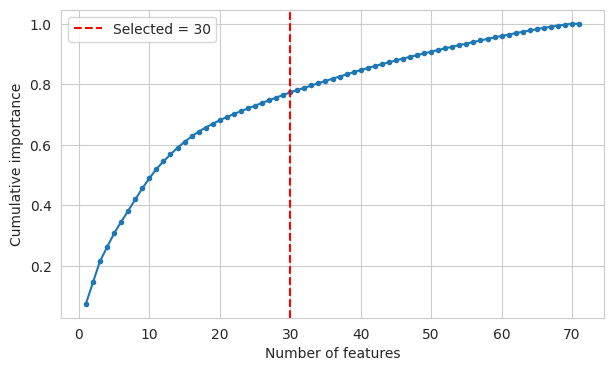

In [26]:
# the cumulative importance shows how quickly the importance adds up
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(importances) + 1), importances.cumsum().values, marker='o', markersize=3)
plt.axvline(top_k, color='red', linestyle='--', label='Selected = %d' % top_k)
plt.xlabel('Number of features')
plt.ylabel('Cumulative importance')
plt.legend()
plt.show()

- The 30 selected features (about a third of the original ones) carry roughly 77% of the total importance, so the remaining features can be removed with little loss

### Checking the effect on the training time

In [27]:
# comparing the training time of the slower models on all the features and on the selected features
def fit_time(model, cols):
    start = time.time()
    model.fit(X_train_t[cols], y_train)
    return time.time() - start

all_cols = list(X_train_t.columns)
timing = []
for name, make_model in [
    ('Random Forest', lambda: RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1)),
    ('Gradient Boosting', lambda: GradientBoostingClassifier(random_state=seed)),
    ('Neural Network', lambda: MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=seed)),
]:
    t_all = fit_time(make_model(), all_cols)
    t_sel = fit_time(make_model(), selected_features)
    timing.append([name, round(t_all, 2), round(t_sel, 2)])

timing_df = pd.DataFrame(timing, columns=['Model', 'Time with all features (s)', 'Time with selected features (s)'])
timing_df

,Model,Time with all features (s),Time with selected features (s)
0,Random Forest,7.52,4.00
1,Gradient Boosting,26.40,8.80
2,Neural Network,3.48,6.73


- The tree-based models train noticeably faster on the selected features. For the Neural Network the time depends mostly on the number of iterations it needs to converge, so it can vary from run to run

In [28]:
# keeping only the selected features in the train and test data
X_train_sel = X_train_t[selected_features]
X_test_sel = X_test_t[selected_features]

print('Train :', X_train_sel.shape)
print('Test  :', X_test_sel.shape)

Train : (5455, 30)
Test  : (1364, 30)


## Balancing the Training Data

We create two balanced versions of the training data and compare them with the original one:

- **SMOTE:** creates new synthetic bankrupt companies by interpolating between existing bankrupt companies and their neighbours, until both classes have the same size
- **Random undersampling:** removes randomly chosen healthy companies until both classes have the same size

The test set is left as it is.

In [29]:
# applying SMOTE and random undersampling on the training data only
X_train_smote, y_train_smote = SMOTE(random_state=seed).fit_resample(X_train_sel, y_train)
X_train_under, y_train_under = RandomUnderSampler(random_state=seed).fit_resample(X_train_sel, y_train)

# all the training sets in one dictionary, so that we can loop over them
datasets = {
    'Original': (X_train_sel, y_train),
    'SMOTE': (X_train_smote, y_train_smote),
    'Undersampling': (X_train_under, y_train_under),
}

for name, (xs, ys) in datasets.items():
    print('%-14s rows = %5d | not bankrupt = %5d | bankrupt = %5d' % (name, len(ys), (ys == 0).sum(), (ys == 1).sum()))

Original       rows =  5455 | not bankrupt =  5279 | bankrupt =   176
SMOTE          rows = 10558 | not bankrupt =  5279 | bankrupt =  5279
Undersampling  rows =   352 | not bankrupt =   176 | bankrupt =   176


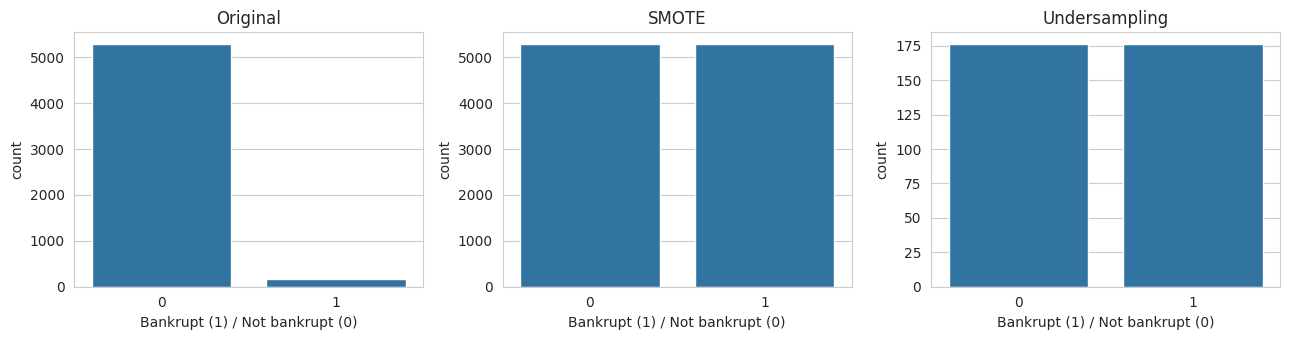

In [30]:
# plotting the class counts of the three training sets
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=False)
for ax, (name, (xs, ys)) in zip(axes, datasets.items()):
    sns.countplot(x=ys, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Bankrupt (1) / Not bankrupt (0)')
plt.tight_layout()
plt.show()

- SMOTE grows the bankrupt class to match the healthy class, while undersampling shrinks the healthy class to match the bankrupt class. Undersampling is faster but throws away most of the healthy companies

## Model Building

### Defining the models

In [31]:
# the six models asked in the problem statement
models = []
models.append(('Logistic Regression', LogisticRegression(max_iter=1000, random_state=seed)))
models.append(('KNN', KNeighborsClassifier(n_neighbors=5)))
models.append(('Decision Tree', DecisionTreeClassifier(random_state=seed)))
models.append(('Neural Network', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=seed)))
models.append(('Random Forest', RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1)))
models.append(('Gradient Boosting', GradientBoostingClassifier(random_state=seed)))

### Training and evaluating the models

Every model is trained on each of the three training sets and evaluated on the same untouched test set. For each model we store the metrics and the confusion matrix values. `FN` (false negatives) are the Type 2 errors and `FP` (false positives) are the Type 1 errors.

In [32]:
results = []
confusion = {}

for data_name, (xs, ys) in datasets.items():
    for model_name, model in models:
        # a fresh copy of the model for every dataset
        m = clone(model)

        start = time.time()
        m.fit(xs, ys)
        train_time = time.time() - start

        # predicting on the test data
        y_pred = m.predict(X_test_sel)
        y_prob = m.predict_proba(X_test_sel)[:, 1]

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
        confusion[(data_name, model_name)] = confusion_matrix(y_test, y_pred)

        results.append({
            'Data': data_name,
            'Model': model_name,
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred, zero_division=0),
            'Recall': recall_score(y_test, y_pred),
            'F1': f1_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_prob),
            'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
            'Train time (s)': train_time,
        })

results_df = pd.DataFrame(results)
print('Done. Models trained:', len(results_df))

Done. Models trained: 18


### Results of all the models

In [33]:
# results table for the original (imbalanced) training data
cols = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC', 'FP', 'FN']
results_df[results_df['Data'] == 'Original'][cols].round(3).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,FP,FN
0,Logistic Regression,0.970,0.636,0.159,0.255,0.947,4,37
1,KNN,0.974,0.800,0.273,0.407,0.854,3,32
2,Decision Tree,0.953,0.308,0.364,0.333,0.668,36,28
3,Neural Network,0.966,0.429,0.205,0.277,0.913,12,35
4,Random Forest,0.971,0.727,0.182,0.291,0.946,3,36
5,Gradient Boosting,0.969,0.538,0.318,0.400,0.950,12,30


In [34]:
# results table after SMOTE
results_df[results_df['Data'] == 'SMOTE'][cols].round(3).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,FP,FN
0,Logistic Regression,0.878,0.192,0.864,0.314,0.946,160,6
1,KNN,0.909,0.237,0.818,0.367,0.883,116,8
2,Decision Tree,0.924,0.224,0.545,0.318,0.741,83,20
3,Neural Network,0.955,0.327,0.386,0.354,0.915,35,27
4,Random Forest,0.963,0.443,0.614,0.514,0.956,34,17
5,Gradient Boosting,0.916,0.254,0.818,0.387,0.953,106,8


In [35]:
# results table after undersampling
results_df[results_df['Data'] == 'Undersampling'][cols].round(3).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,FP,FN
0,Logistic Regression,0.853,0.158,0.818,0.265,0.928,192,8
1,KNN,0.870,0.185,0.886,0.306,0.938,172,5
2,Decision Tree,0.820,0.126,0.773,0.217,0.797,236,10
3,Neural Network,0.861,0.169,0.841,0.281,0.930,182,7
4,Random Forest,0.871,0.186,0.886,0.307,0.953,171,5
5,Gradient Boosting,0.862,0.173,0.864,0.288,0.949,182,6


- On the original data the models have a high accuracy (around 95-97%) but a low recall for the bankrupt class: they miss most of the bankrupt companies
- After balancing, the recall goes up for almost every model while the accuracy and the precision go down. The balanced models flag more companies as bankrupt, which catches more of the real ones but also raises false alarms

## Confusion Matrices

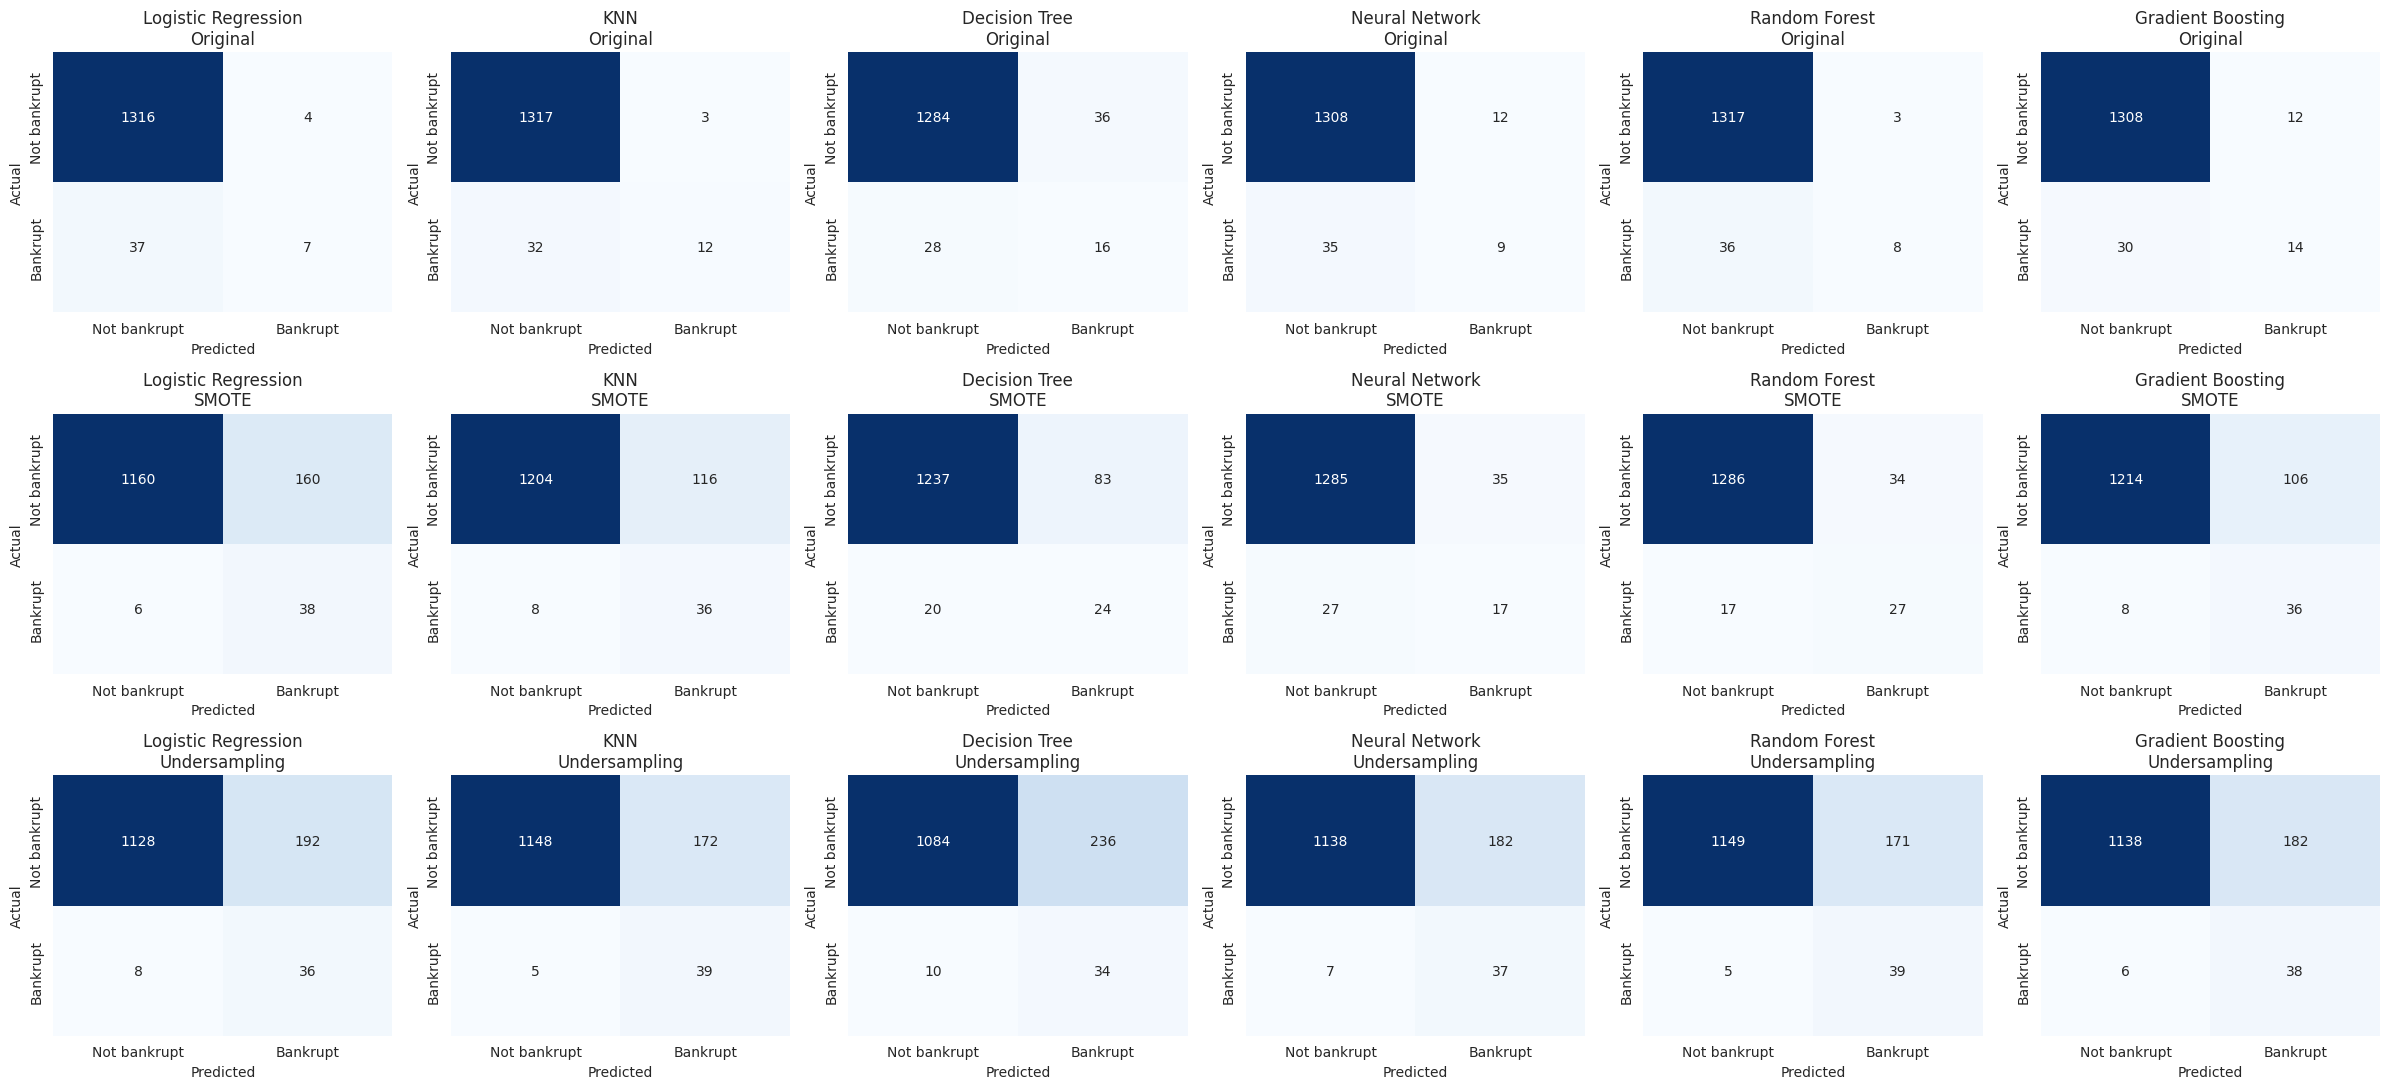

In [36]:
# confusion matrices of every model for the three training sets
fig, axes = plt.subplots(3, 6, figsize=(24, 11))
for i, data_name in enumerate(datasets.keys()):
    for j, (model_name, _) in enumerate(models):
        sns.heatmap(confusion[(data_name, model_name)], annot=True, fmt='d', cmap='Blues',
                    cbar=False, ax=axes[i, j],
                    xticklabels=['Not bankrupt', 'Bankrupt'], yticklabels=['Not bankrupt', 'Bankrupt'])
        axes[i, j].set_title('%s\n%s' % (model_name, data_name))
        axes[i, j].set_xlabel('Predicted')
        axes[i, j].set_ylabel('Actual')
plt.tight_layout()
plt.show()

- In each matrix, the bottom-left cell (actual bankrupt, predicted not bankrupt) is the Type 2 error. It is much smaller in the SMOTE and undersampling rows than in the original row

## Comparison of the Results

### Metrics of the models before and after balancing

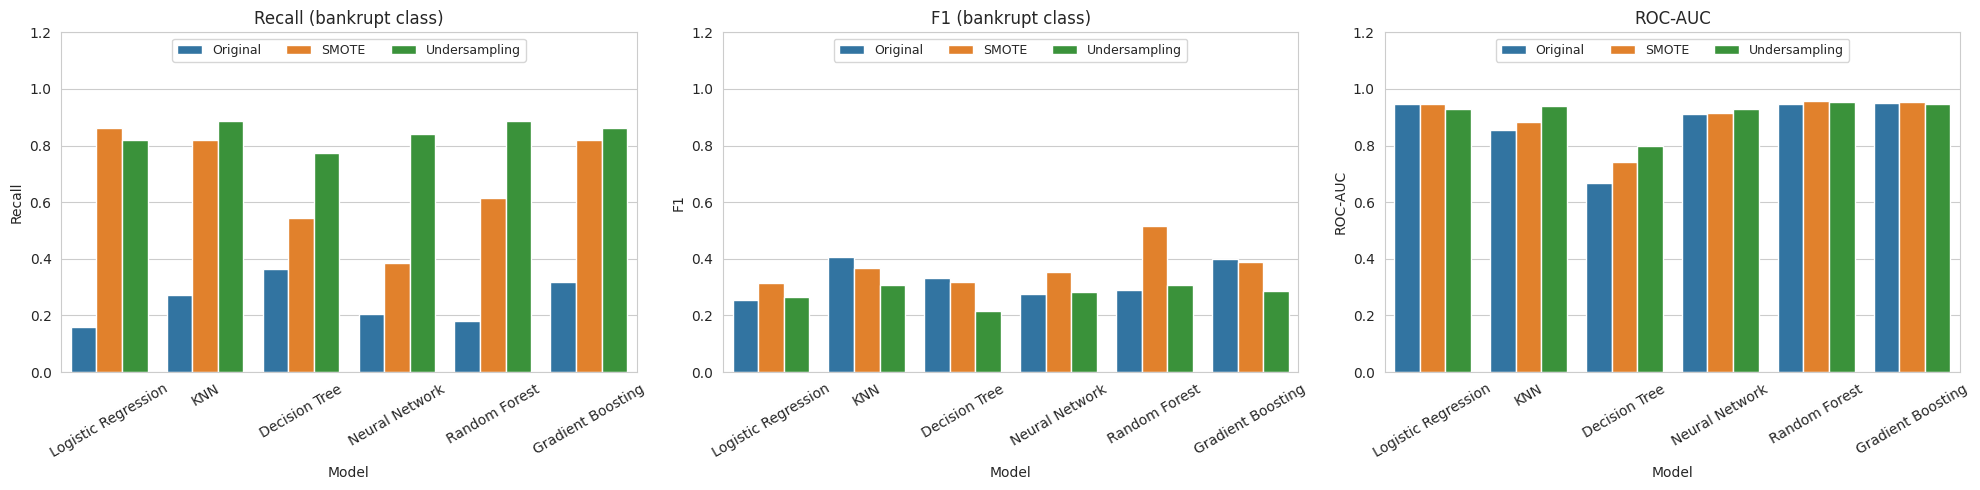

In [37]:
# bar charts of recall, F1-score and ROC-AUC for every model and every training set
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, metric in zip(axes, ['Recall', 'F1', 'ROC-AUC']):
    sns.barplot(x='Model', y=metric, hue='Data', data=results_df, ax=ax)
    ax.set_title(metric + ' (bankrupt class)' if metric != 'ROC-AUC' else metric)
    ax.set_ylim(0, 1.2)
    ax.legend(loc='upper center', ncol=3, fontsize=9)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### Type 2 errors (missed bankruptcies) before and after balancing

In [38]:
# number of bankrupt companies missed (false negatives) for every model
fn_table = results_df.pivot(index='Model', columns='Data', values='FN')[['Original', 'SMOTE', 'Undersampling']]
fn_table['Reduction with SMOTE'] = fn_table['Original'] - fn_table['SMOTE']
fn_table['Reduction with Undersampling'] = fn_table['Original'] - fn_table['Undersampling']

print('Bankrupt companies in the test set:', int(y_test.sum()))
fn_table

Bankrupt companies in the test set: 44


Data,Original,SMOTE,Undersampling,Reduction with SMOTE,Reduction with Undersampling
Model,,,,,
Decision Tree,28,20,10,8,18
Gradient Boosting,30,8,6,22,24
KNN,32,8,5,24,27
Logistic Regression,37,6,8,31,29
Neural Network,35,27,7,8,28
Random Forest,36,17,5,19,31


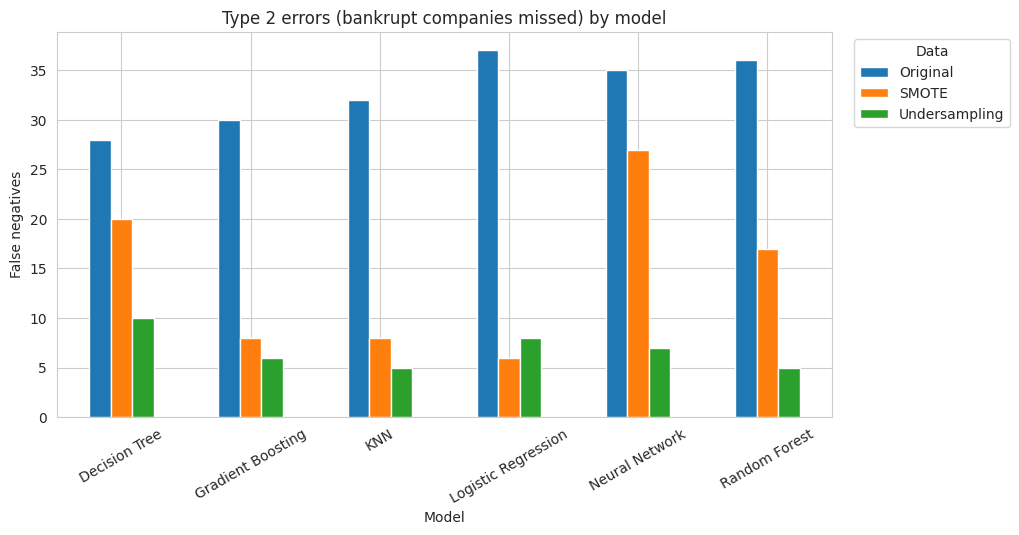

In [39]:
# plotting the Type 2 errors
fn_table[['Original', 'SMOTE', 'Undersampling']].plot(kind='bar', figsize=(10, 5))
plt.title('Type 2 errors (bankrupt companies missed) by model')
plt.ylabel('False negatives')
plt.xticks(rotation=30)
plt.legend(title='Data', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

### Cost of the lower Type 2 errors: Type 1 errors (false alarms)

In [40]:
# number of healthy companies wrongly flagged as bankrupt (false positives) for every model
fp_table = results_df.pivot(index='Model', columns='Data', values='FP')[['Original', 'SMOTE', 'Undersampling']]

print('Healthy companies in the test set:', int((y_test == 0).sum()))
fp_table

Healthy companies in the test set: 1320


Data,Original,SMOTE,Undersampling
Model,,,
Decision Tree,36,83,236
Gradient Boosting,12,106,182
KNN,3,116,172
Logistic Regression,4,160,192
Neural Network,12,35,182
Random Forest,3,34,171


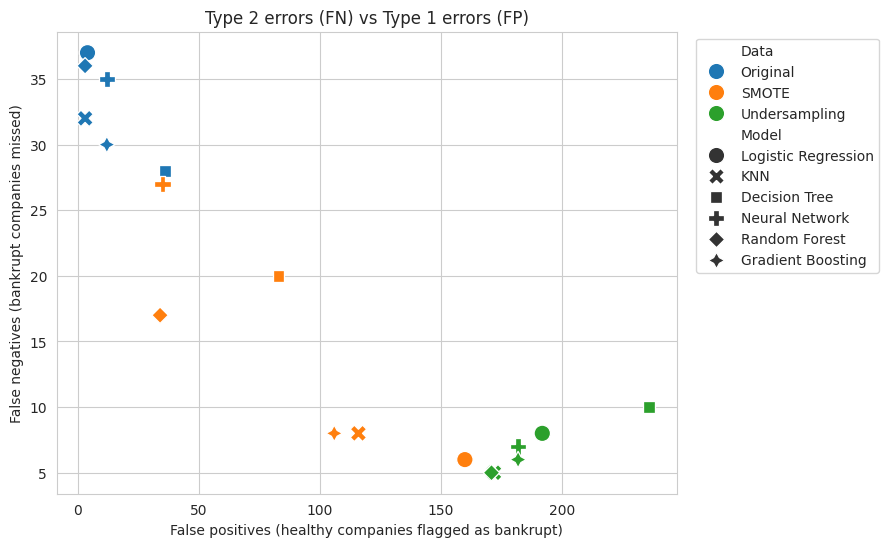

In [41]:
# Type 2 errors against Type 1 errors for every model and training set
plt.figure(figsize=(8, 6))
sns.scatterplot(x='FP', y='FN', hue='Data', style='Model', data=results_df, s=140)
plt.title('Type 2 errors (FN) vs Type 1 errors (FP)')
plt.xlabel('False positives (healthy companies flagged as bankrupt)')
plt.ylabel('False negatives (bankrupt companies missed)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

- Balancing moves the models towards the bottom-right of the plot: fewer missed bankruptcies (lower) but more false alarms (further right). Undersampling reduces the Type 2 errors the most and increases the false alarms the most, while SMOTE sits in between

## Key Findings

In [42]:
# printing the main findings directly from the results table
orig = results_df[results_df['Data'] == 'Original'].set_index('Model')
smote = results_df[results_df['Data'] == 'SMOTE'].set_index('Model')
under = results_df[results_df['Data'] == 'Undersampling'].set_index('Model')

print('1. Average recall of the bankrupt class across the six models:')
print('   Original = %.2f | SMOTE = %.2f | Undersampling = %.2f' %
      (orig['Recall'].mean(), smote['Recall'].mean(), under['Recall'].mean()))

print('\n2. Average Type 2 errors (missed bankruptcies) per model:')
print('   Original = %.1f | SMOTE = %.1f | Undersampling = %.1f  (out of %d)' %
      (orig['FN'].mean(), smote['FN'].mean(), under['FN'].mean(), y_test.sum()))

print('\n3. Average Type 1 errors (false alarms) per model:')
print('   Original = %.1f | SMOTE = %.1f | Undersampling = %.1f  (out of %d)' %
      (orig['FP'].mean(), smote['FP'].mean(), under['FP'].mean(), (y_test == 0).sum()))

print('\n4. Models with fewer Type 2 errors after SMOTE        :', int((smote['FN'] < orig['FN']).sum()), 'of 6')
print('   Models with fewer Type 2 errors after undersampling :', int((under['FN'] < orig['FN']).sum()), 'of 6')

best_f1 = results_df.sort_values('F1', ascending=False).iloc[0]
best_rec = results_df.sort_values(['Recall', 'F1'], ascending=False).iloc[0]
print('\n5. Best F1-score        : %s on %s data (F1 = %.3f, missed = %d, false alarms = %d)' %
      (best_f1['Model'], best_f1['Data'], best_f1['F1'], best_f1['FN'], best_f1['FP']))
print('   Highest recall       : %s on %s data (recall = %.3f, missed = %d, false alarms = %d)' %
      (best_rec['Model'], best_rec['Data'], best_rec['Recall'], best_rec['FN'], best_rec['FP']))

1. Average recall of the bankrupt class across the six models:
   Original = 0.25 | SMOTE = 0.67 | Undersampling = 0.84

2. Average Type 2 errors (missed bankruptcies) per model:
   Original = 33.0 | SMOTE = 14.3 | Undersampling = 6.8  (out of 44)

3. Average Type 1 errors (false alarms) per model:
   Original = 11.7 | SMOTE = 89.0 | Undersampling = 189.2  (out of 1320)

4. Models with fewer Type 2 errors after SMOTE        : 6 of 6
   Models with fewer Type 2 errors after undersampling : 6 of 6

5. Best F1-score        : Random Forest on SMOTE data (F1 = 0.514, missed = 17, false alarms = 34)
   Highest recall       : Random Forest on Undersampling data (recall = 0.886, missed = 5, false alarms = 171)


## Checking the Stability of the Results

The test set has only a few dozen bankrupt companies, so the numbers of one split can change a lot with a different random split. To check that the conclusions hold, we repeat the whole pipeline (split, transformation, feature selection, balancing, training) for a few more random seeds and average the results. This cell takes a few minutes.

In [43]:
def run_pipeline(seed_value):
    """Runs the complete pipeline for one random seed and returns the results as a dataframe"""
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed_value)

    # transformation
    q = QuantileTransformer(output_distribution='normal', n_quantiles=1000, random_state=seed_value)
    Xtr = pd.DataFrame(q.fit_transform(Xtr), columns=X.columns)
    Xte = pd.DataFrame(q.transform(Xte), columns=X.columns)

    # feature selection
    c = Xtr.corr().abs()
    up = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
    keep = [col for col in Xtr.columns if not (up[col] > corr_threshold).any()]
    rf = RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', random_state=seed_value, n_jobs=-1)
    rf.fit(Xtr[keep], ytr)
    sel = list(pd.Series(rf.feature_importances_, index=keep).sort_values(ascending=False).head(top_k).index)
    Xtr, Xte = Xtr[sel], Xte[sel]

    # balancing
    sets = {
        'Original': (Xtr, ytr),
        'SMOTE': SMOTE(random_state=seed_value).fit_resample(Xtr, ytr),
        'Undersampling': RandomUnderSampler(random_state=seed_value).fit_resample(Xtr, ytr),
    }

    rows = []
    for data_name, (xs, ys) in sets.items():
        for model_name, model in models:
            m = clone(model)
            if 'random_state' in m.get_params():
                m.set_params(random_state=seed_value)
            m.fit(xs, ys)
            pred = m.predict(Xte)
            tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
            rows.append({'Seed': seed_value, 'Data': data_name, 'Model': model_name,
                         'Recall': recall_score(yte, pred), 'Precision': precision_score(yte, pred, zero_division=0),
                         'F1': f1_score(yte, pred), 'FN': fn, 'FP': fp})
    return pd.DataFrame(rows)

seeds = [7, 123, 2024]
robust_df = pd.concat([run_pipeline(s) for s in seeds], ignore_index=True)

# average over the seeds
summary = robust_df.groupby(['Model', 'Data'])[['Recall', 'Precision', 'F1', 'FN', 'FP']].mean().round(3)
summary

Recall  Precision     F1      FN       FP
Model               Data                                                    
Decision Tree       Original        0.341      0.287  0.311  29.000   37.000
                    SMOTE           0.455      0.247  0.320  24.000   61.000
                    Undersampling   0.780      0.127  0.219   9.667  235.000
Gradient Boosting   Original        0.265      0.538  0.355  32.333   10.333
                    SMOTE           0.712      0.247  0.367  12.667   96.000
                    Undersampling   0.848      0.166  0.277   6.667  188.333
KNN                 Original        0.197      0.432  0.270  35.333   11.667
                    SMOTE           0.712      0.221  0.337  12.667  112.000
                    Undersampling   0.871      0.157  0.265   5.667  212.667
Logistic Regression Original        0.205      0.605  0.302  35.000    6.000
                    SMOTE           0.773      0.178  0.288  10.000  158.333
                    Undersampling   0.841      0.164  0.275   7.000  189.000
Neural Network      Original        0.303      0.403  0.344  30.667   19.667
                    SMOTE           0.394      0.413  0.401  26.667   25.667
                    Undersampling   0.841      0.165  0.275   7.000  189.667
Random Forest       Original        0.182      0.726  0.288  36.000    3.000
                    SMOTE           0.500      0.379  0.431  22.000   37.000
                    Undersampling   0.864      0.169  0.283   6.000  189.000

In [44]:
# in how many of the seeds did balancing reduce the Type 2 errors of each model
fn_pivot = robust_df.pivot_table(index=['Model', 'Seed'], columns='Data', values='FN')
check = pd.DataFrame({
    'SMOTE fewer FN (seeds)': (fn_pivot['SMOTE'] < fn_pivot['Original']).groupby('Model').sum(),
    'Undersampling fewer FN (seeds)': (fn_pivot['Undersampling'] < fn_pivot['Original']).groupby('Model').sum(),
})
print('Out of %d seeds:' % len(seeds))
check

Out of 3 seeds:


,SMOTE fewer FN (seeds),Undersampling fewer FN (seeds)
Model,,
Decision Tree,3,3
Gradient Boosting,3,3
KNN,3,3
Logistic Regression,3,3
Neural Network,3,3
Random Forest,3,3


In [45]:
# best model by average F1-score over the seeds
best_avg = summary.sort_values('F1', ascending=False).head(5)
best_avg

Recall  Precision     F1      FN      FP
Model             Data                                              
Random Forest     SMOTE      0.500      0.379  0.431  22.000  37.000
Neural Network    SMOTE      0.394      0.413  0.401  26.667  25.667
Gradient Boosting SMOTE      0.712      0.247  0.367  12.667  96.000
                  Original   0.265      0.538  0.355  32.333  10.333
Neural Network    Original   0.303      0.403  0.344  30.667  19.667

## Observations and Insights

- **Accuracy is misleading:** on the original data every model has an accuracy of 95% or more, but most of them miss two-thirds or more of the bankrupt companies. A model that predicts "not bankrupt" for everyone would score about 97%
- **Balancing reduces Type 2 errors:** with SMOTE and with undersampling, the number of missed bankruptcies goes down for almost every model, and the recall of the bankrupt class goes up from roughly 0.2-0.4 to 0.8-0.9 with undersampling, and to 0.5-0.9 with SMOTE for five of the six models
- **There is a cost:** the models raise more false alarms (Type 1 errors) and the precision falls. Undersampling gives the lowest Type 2 errors but flags a large number of healthy companies, since it trains on very little data. SMOTE gives a better balance between the two errors
- **Best model:** Random Forest with SMOTE gives the best F1-score in our runs, with a good ROC-AUC. If missing a bankruptcy is much more costly than a false alarm, the high-recall options (for example undersampling or Logistic Regression with SMOTE) can be preferred
- **Neural Network:** its recall hardly changes with SMOTE in our runs (it gains only with undersampling), so we should not assume that balancing helps equally for every model
- **Dimensionality reduction:** keeping 30 of the 94 features kept most of the importance and made the tree-based models faster to train
- **Limitation:** the test set has only a few dozen bankrupt companies, so single numbers should be read with care. The multi-seed check shows the direction of the results is stable even if the exact values change

## Summary

- The dataset has 6,819 companies and only about 3.2% of them are bankrupt, so accuracy alone is not a useful measure and we focused on recall, F1-score and the Type 2 errors
- We removed a constant feature and the near-duplicate features, and kept the 30 most important features using Random Forest importance, which reduced the training time of the tree-based models
- We trained Logistic Regression, KNN, Decision Tree, Neural Network, Random Forest and Gradient Boosting on the original data and on the SMOTE and undersampled data
- Balancing cut the Type 2 errors for nearly every model, at the cost of more false alarms. Random Forest with SMOTE gave the best overall balance
- To improve the results further, we can tune the hyperparameters, set a lower decision threshold, try class weights or combined methods like SMOTE with Tomek links, and use cross-validation on the full data

___